In [128]:
## Lauro Uriel Cortes Salazar
## Importación de librerías necesarias
import pandas as pd
import matplotlib.pyplot as plt

In [129]:
## Carga de datos desde un archivo CSV
df = pd.read_csv('Datos_actividad_2.csv')
df.head()

,Sucursal,Fecha,Ingresos,Gastos
0,Sucursal1,1/1/2023,12000,8500
1,Sucursal2,1/1/2023,15000,13000
2,Sucursal3,1/1/2023,10000,7500
3,Sucursal4,1/1/2023,9000,6000
4,Sucursal1,1/8/2023,13000,9000


In [130]:
## Tipos de datos de cada columna
print("\nTipos de datos de cada columna:")
print(df.dtypes)

## Valores nulos en cada columna
print("\nValores nulos en cada columna:")
print(df.isnull().sum())

## Valores duplicados en cada columna
print("\nValores duplicados en cada columna:")
print(df.duplicated().sum())

## Conversión de la columna 'Fecha' a tipo datetime
df['Fecha'] = pd.to_datetime(df['Fecha'], format='%m/%d/%Y')
print("\nTipos de datos de cada columna después de la conversión:")
print(df.dtypes)
df.describe().round(2)


Tipos de datos de cada columna:
Sucursal      str
Fecha         str
Ingresos    int64
Gastos      int64
dtype: object

Valores nulos en cada columna:
Sucursal    0
Fecha       0
Ingresos    0
Gastos      0
dtype: int64

Valores duplicados en cada columna:
0

Tipos de datos de cada columna después de la conversión:
Sucursal               str
Fecha       datetime64[us]
Ingresos             int64
Gastos               int64
dtype: object


,Fecha,Ingresos,Gastos
count,88,88.00,88.00
mean,2023-03-15 12:00:00,21793.41,18319.66
min,2023-01-01 00:00:00,1500.00,3320.00
25%,2023-02-05 00:00:00,16000.00,13000.00
50%,2023-03-15 12:00:00,22000.00,18000.00
75%,2023-04-23 00:00:00,28000.00,24000.00
max,2023-05-28 00:00:00,36000.00,34000.00
std,NaN,7139.37,7066.50


In [131]:
## Cálculo de la ganancia
df['Ganancia'] = df['Ingresos'] - df['Gastos']

## Cálculo del margen de ganancia
df['Margen de Ganancia'] = ((df['Ganancia'] / df['Ingresos']) * 100).round(2)

## Ganancia neta total
print("\nGanancia neta total:")
print(f"${df['Ganancia'].sum():,.2f}")

## Margen de ganancia general
print("\nMargen de ganancia general:")
print(round(df['Ganancia'].sum() / df['Ingresos'].sum() * 100, 2), '%')

## Margen con mayor margen de ganancia
print("\nMayor margen de ganancia:")
print(df.loc[df['Margen de Ganancia'].idxmax(), ['Sucursal','Ganancia', 'Margen de Ganancia', 'Ingresos', 'Gastos', ]].to_string())

## Margen con menor margen de ganancia
print("\nMenor margen de ganancia:")
print(df.loc[df['Margen de Ganancia'].idxmin(), ['Sucursal','Ganancia', 'Margen de Ganancia', 'Ingresos', 'Gastos', ]].to_string())

## Visualización de la ganancia por sucursal
df.head()


Ganancia neta total:
$305,690.00

Margen de ganancia general:
15.94 %

Mayor margen de ganancia:
Sucursal              Sucursal3
Ganancia                  11320
Margen de Ganancia        39.97
Ingresos                  28320
Gastos                    17000

Menor margen de ganancia:
Sucursal              Sucursal4
Ganancia                  -1820
Margen de Ganancia      -121.33
Ingresos                   1500
Gastos                     3320


,Sucursal,Fecha,Ingresos,Gastos,Ganancia,Margen de Ganancia
0,Sucursal1,2023-01-01,12000,8500,3500,29.17
1,Sucursal2,2023-01-01,15000,13000,2000,13.33
2,Sucursal3,2023-01-01,10000,7500,2500,25.00
3,Sucursal4,2023-01-01,9000,6000,3000,33.33
4,Sucursal1,2023-01-08,13000,9000,4000,30.77


Líder en ingresos:
Sucursal2 con ingresos de $ 561000

Líder en gastos:
Sucursal2 con gastos de $ 517000


,Ingresos,Gastos,Ganancia,Margen de Ganancia,Gastos/Ingresos
Sucursal,,,,,
Sucursal2,561000,517000,44000,7.84,92.16
Sucursal1,495000,388000,107000,21.62,78.38
Sucursal3,458320,367500,90820,19.82,80.18
Sucursal4,403500,339630,63870,15.83,84.17


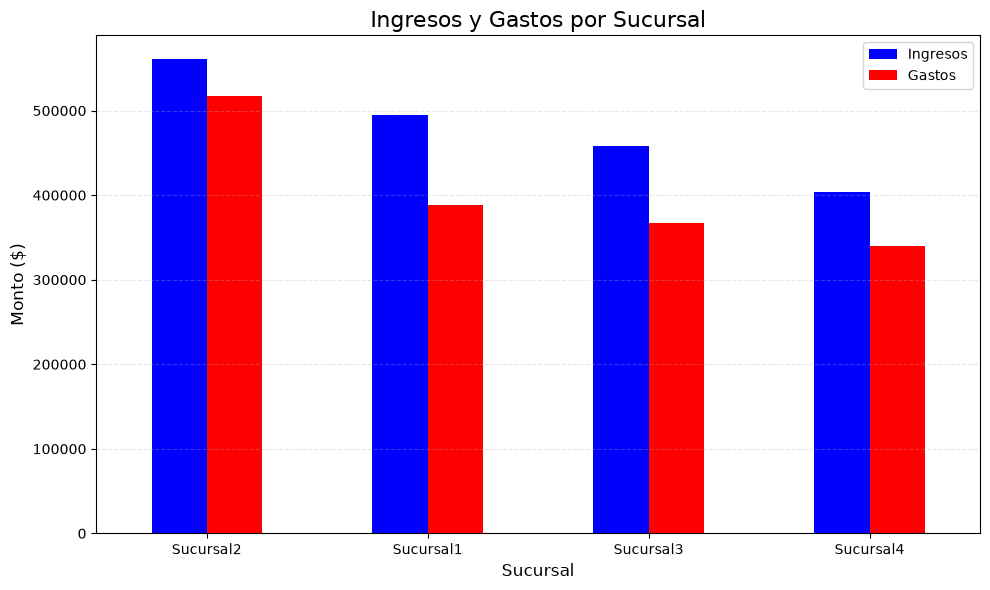

In [132]:
## Resumen por sucursal
resumen_s=df.groupby('Sucursal')[['Ingresos','Gastos','Ganancia']].sum().sort_values(by='Ganancia', ascending=False)

## Cálculo del margen de ganancia por sucursal
resumen_s['Margen de Ganancia'] = ((resumen_s['Ganancia'] / resumen_s['Ingresos']) * 100).round(2)

## Cálculo del porcentaje de gastos sobre ingresos por sucursal
resumen_s['Gastos/Ingresos'] = ((resumen_s['Gastos'] / resumen_s['Ingresos']) * 100).round(2)

## Ordenar el resumen por ingresos de manera descendente
resumen_s=resumen_s.sort_values(by='Ingresos', ascending=False)

## Mostrar la sucursal con los mayores ingresos
print("Líder en ingresos:")
print(resumen_s['Ingresos'].idxmax(), "con ingresos de $", resumen_s['Ingresos'].max())

## Mostrar la sucursal con mayores gastos
print("\nLíder en gastos:")
print(resumen_s['Gastos'].idxmax(), "con gastos de $", resumen_s['Gastos'].max())

## Mostrar la tabla del resumen por sucursal
display(resumen_s)

## Gráfico de barras de ingresos y gastos por sucursal
ax = resumen_s[['Ingresos', 'Gastos']].plot(kind='bar',color=['blue', 'red'], figsize=(10, 6))
ax.set_title('Ingresos y Gastos por Sucursal', fontsize=16)
ax.set_xlabel('Sucursal', fontsize=12)
ax.set_ylabel('Monto ($)', fontsize=12)
ax.grid(axis='y', linestyle='--', alpha=0.3)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Resumen de Ganancia por Sucursal:


,Ganancia Promedio,Desviación Estándar,Coeficiente de Variación,Margen de Ganancia Promedio
Sucursal,,,,
Sucursal4,2903.18,1200.44,41.35,12.01
Sucursal3,4128.18,1675.75,40.59,20.88
Sucursal1,4863.64,383.65,7.89,23.21
Sucursal2,2000.00,0.00,0.00,8.39


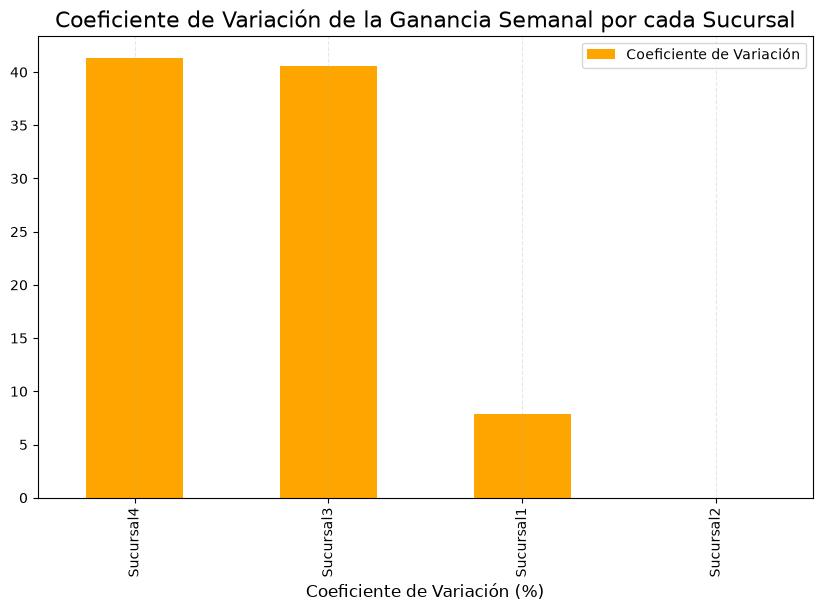

In [133]:
## Cálculo del coeficiente de variación de la ganancia de cada sucursal
disp=df.groupby('Sucursal')['Ganancia'].agg(['mean','std'])

disp.columns = ['Ganancia Promedio', 'Desviación Estándar']

## Cálculo del coeficiente de variación
disp['Coeficiente de Variación'] = (disp['Desviación Estándar'] / disp['Ganancia Promedio'] * 100).round(2)

## Cálculo del margen de ganancia promedio por cada sucursal
disp['Margen de Ganancia Promedio'] = df.groupby('Sucursal')['Margen de Ganancia'].mean().round(2)

disp = disp.round(2).sort_values(by='Coeficiente de Variación', ascending=False)

## Mostrar el resumen de ganancia por cada sucursal
print("\nResumen de Ganancia por Sucursal:")
display(disp)

## Gráfico de barras del coeficiente de variación de la ganancia semanal por cada sucursal
ax = disp[['Coeficiente de Variación']].sort_values(by='Coeficiente de Variación', ascending=False).plot(kind='bar', figsize=(10, 6), color='orange')
ax.set_title('Coeficiente de Variación de la Ganancia Semanal por cada Sucursal', fontsize=16)
ax.set_xlabel('Coeficiente de Variación (%)', fontsize=12)
ax.set_ylabel('')
ax.grid(axis='x', linestyle='--', alpha=0.3)
plt.show()

,Ingresos,Gastos,Ganancia,Semanas,Margen de Ganancia
Mes,,,,,
Enero,270000,207500,62500,5,23.15
Febrero,288000,232000,56000,4,19.44
Marzo,359320,293310,66010,4,18.37
Abril,530000,460000,70000,5,13.21
Mayo,470500,419320,51180,4,10.88


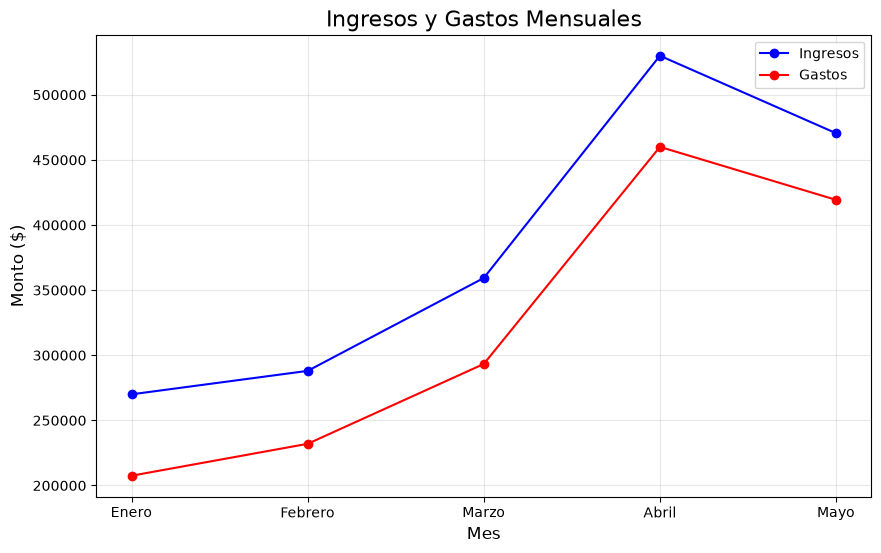

In [134]:
## Cálculo del mes a partir de la columna 'Fecha'
df['Mes'] = df['Fecha'].dt.month

## Agrupación de los datos por mes y cálculo de la suma de ingresos, gastos y ganancia, así como el número de semanas en cada mes
resumen_m = df.groupby('Mes').agg({'Ingresos': 'sum','Gastos': 'sum','Ganancia': 'sum', 'Fecha': 'nunique'}).sort_index()

## Renombrar la columna 'Fecha' a 'Semanas' para reflejar el número de semanas en cada mes
resumen_m.rename(columns={'Fecha': 'Semanas'}, inplace=True)

## Cálculo del margen de la ganancia mensual
resumen_m['Margen de Ganancia'] = ((resumen_m['Ganancia'] / resumen_m['Ingresos']) * 100).round(2)

## Mapeo de los números de mes a nombres de mes
resumen_m.index = resumen_m.index.map({1:'Enero', 2:'Febrero', 3:'Marzo', 4:'Abril', 5:'Mayo', 6:'Junio', 7:'Julio', 8:'Agosto', 9:'Septiembre', 10:'Octubre', 11:'Noviembre', 12:'Diciembre'})

display(resumen_m)

## Gráfico de línea de los ingresos y de los gastos mensuales
plt.figure(figsize=(10, 6))
plt.plot(resumen_m.index, resumen_m['Ingresos'], marker='o', label='Ingresos', color='blue')
plt.plot(resumen_m.index, resumen_m['Gastos'], marker='o', label='Gastos', color='red')
plt.title('Ingresos y Gastos Mensuales', fontsize=16)
plt.xlabel('Mes', fontsize=12)
plt.ylabel('Monto ($)', fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [135]:
## Agrupación de los datos por semana
sem = df.groupby('Fecha')[['Ingresos', 'Gastos', 'Ganancia']].sum().sort_index()

## Cálculo del margen de ganancia
sem['Margen de Ganancia'] = ((sem['Ganancia'] / sem['Ingresos']) * 100).round(2)

## Cálculo del límite superior para seleccionar las semanas con el mayor margen de ganancia
limite_superior = sem['Margen de Ganancia'].sort_values(ascending=False).iloc[4]

## Selección de las semanas con el mayor margen de ganancia
top = sem[sem['Margen de Ganancia'] >= limite_superior].sort_values(by='Margen de Ganancia', ascending=False)

print("\nTop 5 semanas con mayor margen de ganancia:")
display(top)

## Cálculo del límite inferior para seleccionar las semanas con el menor margen de ganancia
limite_inferior = df[(df['Margen de Ganancia'] < 0) | (df['Margen de Ganancia'] < 10)]

print("\nSemanas con margen de ganancia menor al 10% o negativo:")
display(limite_inferior[['Fecha','Mes', 'Sucursal', 'Ingresos', 'Gastos', 'Ganancia', 'Margen de Ganancia']].sort_values(by='Margen de Ganancia', ascending=True).head(5))


Top 5 semanas con mayor margen de ganancia:


,Ingresos,Gastos,Ganancia,Margen de Ganancia
Fecha,,,,
2023-03-19,97320,73310,24010,24.67
2023-01-01,46000,35000,11000,23.91
2023-01-22,58000,44500,13500,23.28
2023-01-15,54000,41500,12500,23.15
2023-01-08,50000,38500,11500,23.00



Semanas con margen de ganancia menor al 10% o negativo:


,Fecha,Mes,Sucursal,Ingresos,Gastos,Ganancia,Margen de Ganancia
75,2023-05-07,5,Sucursal4,1500,3320,-1820,-121.33
85,2023-05-28,5,Sucursal2,36000,34000,2000,5.56
81,2023-05-21,5,Sucursal2,35000,33000,2000,5.71
77,2023-05-14,5,Sucursal2,34000,32000,2000,5.88
73,2023-05-07,5,Sucursal2,33000,31000,2000,6.06


In [136]:
## Cálculo del margen de ganancia
margen = df['Ganancia'].sum() / df['Ingresos'].sum() * 100
print("\nMargen de ganancia promedio:")
print(round(margen, 2), '%')

brecha = resumen_s[['Ingresos', 'Gastos', 'Ganancia', 'Margen de Ganancia']].copy()

## Cálculo de la brecha de margen de ganancia por cada sucursal
brecha['Brecha vs margen'] = (brecha['Margen de Ganancia'] - margen).round(2)

## Cálculo de la brecha de margen de ganancia respecto a la sucursal con el mayor margen de ganancia
brecha['Brecha vs sucursal'] = (brecha['Margen de Ganancia'] - brecha['Margen de Ganancia'].max()).round(2)

## Cálculo de los ahorros que se necesitan para alcanzar el margen de ganancia
brecha['Ahorros que ocupan'] = (brecha['Ingresos'] * margen / 100 - brecha['Ganancia']).clip(lower=0).round(2)

brecha = brecha.sort_values(by='Brecha vs margen', ascending=True)
display(brecha[['Ingresos', 'Gastos', 'Ganancia', 'Margen de Ganancia', 'Brecha vs margen', 'Brecha vs sucursal', 'Ahorros que ocupan']])

## Alertas de margen de ganancia bajo o negativo
alert = df.copy()
alert['Alerta'] = ''

## Alertas de margen de ganancia en bajo
alert.loc[alert['Margen de Ganancia'] < 10, 'Alerta'] = 'Bajo < 10%'

## Alertas de margen de ganancia en pérdida
alert.loc[alert['Margen de Ganancia'] < 0, 'Alerta'] = 'Pérdida < 0%'

alert['Fecha'] = alert['Fecha'].dt.strftime('%Y-%m-%d')
display(alert[['Fecha', 'Sucursal', 'Ingresos', 'Gastos', 'Ganancia', 'Margen de Ganancia', 'Alerta']].sort_values(by='Margen de Ganancia', ascending=True))



Margen de ganancia promedio:
15.94 %


,Ingresos,Gastos,Ganancia,Margen de Ganancia,Brecha vs margen,Brecha vs sucursal,Ahorros que ocupan
Sucursal,,,,,,,
Sucursal2,561000,517000,44000,7.84,-8.10,-13.78,45420.33
Sucursal4,403500,339630,63870,15.83,-0.11,-5.79,445.69
Sucursal3,458320,367500,90820,19.82,3.88,-1.80,0.00
Sucursal1,495000,388000,107000,21.62,5.68,0.00,0.00


,Fecha,Sucursal,Ingresos,Gastos,Ganancia,Margen de Ganancia,Alerta
75,2023-05-07,Sucursal4,1500,3320,-1820,-121.33,Pérdida < 0%
85,2023-05-28,Sucursal2,36000,34000,2000,5.56,Bajo < 10%
81,2023-05-21,Sucursal2,35000,33000,2000,5.71,Bajo < 10%
77,2023-05-14,Sucursal2,34000,32000,2000,5.88,Bajo < 10%
73,2023-05-07,Sucursal2,33000,31000,2000,6.06,Bajo < 10%
...,...,...,...,...,...,...,...
16,2023-01-29,Sucursal1,16000,11000,5000,31.25,
8,2023-01-15,Sucursal1,14000,9500,4500,32.14,
12,2023-01-22,Sucursal1,15000,10000,5000,33.33,
3,2023-01-01,Sucursal4,9000,6000,3000,33.33,
